In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [11]:
def extract_petri_dish(image):
    #convert the picture to gray if it wasn't already also computer doen't need color to find shapes.
    gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    #removing noise and keep the image smooth
    # I chose the gaussian blur because it is effective in reducing image noise and detail.
    blurred=cv2.GaussianBlur(gray,(11,11),0)
    # Use adaptive thresholding to handle different lighting conditions for different images
    thresh = cv2.adaptiveThreshold(blurred, 255,
                                   cv2.ADAPTIVE_THRESH_MEAN_C,
                                   cv2.THRESH_BINARY_INV, 51, 5)
    kernel = np.ones((5, 5), np.uint8)
    # Close gaps in the thresholded image
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
    # Find contours in the closed image
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if 0.8 < w / h < 1.2 and w > 200:
            size = max(w, h)
            cx, cy = x + w // 2, y + h // 2
            half = size // 2

            x1 = max(0, cx - half)
            y1 = max(0, cy - half)
            x2 = min(image.shape[1], cx + half)
            y2 = min(image.shape[0], cy + half)

            cropped = image[y1:y2, x1:x2]
            return cropped

    h, w = image.shape[:2]
    side = min(h, w)
    startx = (w - side) // 2
    starty = (h - side) // 2
    return image[starty:starty + side, startx:startx + side]

In [14]:
def segment_plants_in_dish(image_path):
    """
    Loads an image, extracts the petri dish, and segments plants inside it.
    
    Returns:
        cropped_dish: The extracted Petri dish image (BGR)
        binary_mask: The binary mask used for segmentation (for visualization/debug)
        colored_mask: The segmented image with colored plants
    """
    # Load original image
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(f"Failed to load image from {image_path}")
    
    # Step 1: Extract the petri dish (crop to square area)
    cropped_dish = extract_petri_dish(image)
    
    # Step 2: Segment plants inside the dish (same as segment_plants)
    gray = cv2.cvtColor(cropped_dish, cv2.COLOR_BGR2GRAY)
    gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(blurred.astype(np.uint8))

    _, binary = cv2.threshold(enhanced, 140, 255, cv2.THRESH_BINARY_INV)
    kernel = np.ones((3, 3), np.uint8)
    binary = cv2.dilate(binary, kernel, iterations=1)
    
    retval, labels, stats, centroids = cv2.connectedComponentsWithStats(binary)
    
    edge_mask = np.zeros_like(labels, dtype=bool)
    edge_mask[0:260, :] = True
    edge_mask[-300:, :] = True
    edge_mask[:, 0:200] = True
    edge_mask[:, -140:] = True

    plant_colors = [
        [180, 120, 240],
        [240, 180, 120],
        [120, 240, 180],
        [180, 240, 120],
        [240, 120, 180],
    ]
    
    background_color = [20, 20, 30]
    colored_mask = np.ones((binary.shape[0], binary.shape[1], 3), dtype=np.uint8)
    colored_mask[:] = background_color

    valid_plants = []
    for i in range(1, retval):
        x, y, w, h, area = stats[i]
        if (
            area > 1500 and
            h > 200 and
            h/w > 0.4 and
            y < binary.shape[0]*0.95 and
            w < binary.shape[1]*0.5
        ):
            valid_plants.append((i, h, x))

    valid_plants.sort(key=lambda x: x[2])

    for color_idx, (plant_label, _, _) in enumerate(valid_plants):
        if color_idx < len(plant_colors):
            mask = (labels == plant_label) & ~edge_mask
            colored_mask[mask] = plant_colors[color_idx]

    return cropped_dish, binary, colored_mask


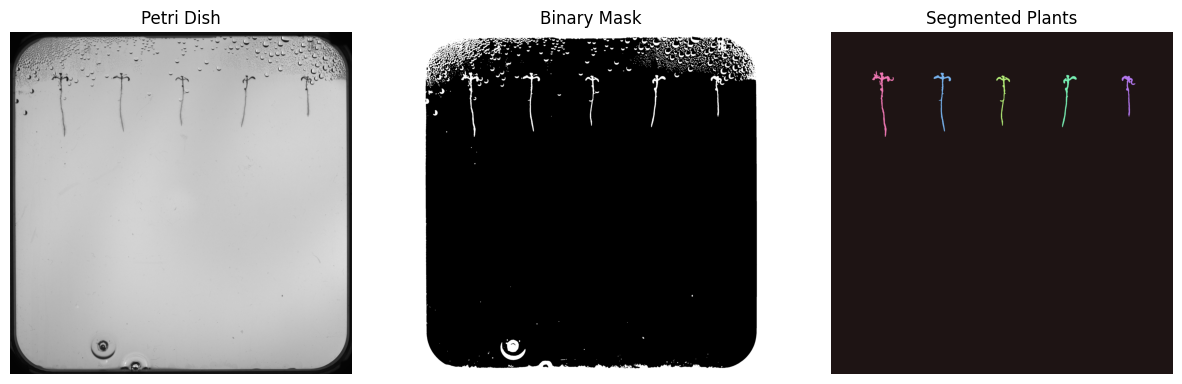

In [15]:
dish, mask, result = segment_plants_in_dish(r"E:\Github\Block A 2\2025-26b-fai2-adsai-MohammadaliJaberi244437\Task_3\pictures\task_3_image_1.png")

# Show with matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
plt.subplot(1,3,1)
plt.title("Petri Dish")
plt.imshow(cv2.cvtColor(dish, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Binary Mask")
plt.imshow(mask, cmap='gray')
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Segmented Plants")
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


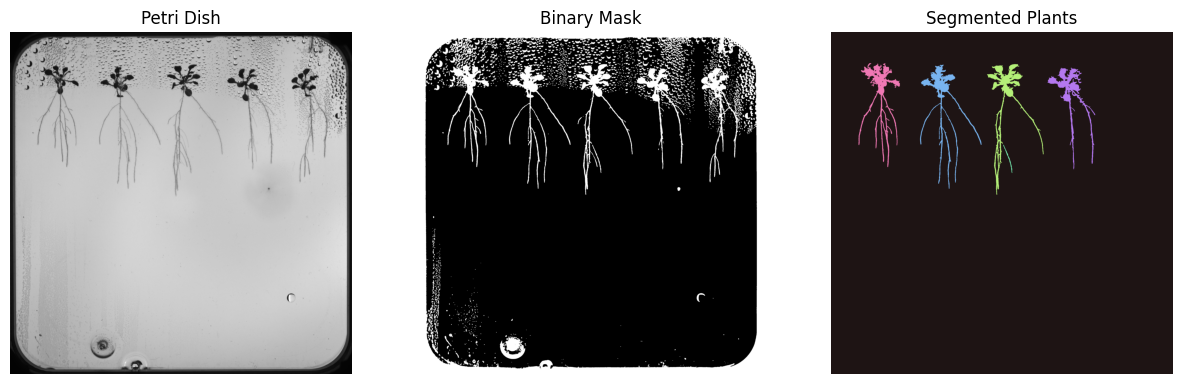

In [16]:
dish, mask, result = segment_plants_in_dish(r"E:\Github\Block A 2\2025-26b-fai2-adsai-MohammadaliJaberi244437\Task_3\pictures\task_3_image_2.png")

# Show with matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
plt.subplot(1,3,1)
plt.title("Petri Dish")
plt.imshow(cv2.cvtColor(dish, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Binary Mask")
plt.imshow(mask, cmap='gray')
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Segmented Plants")
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
